In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

Dataset Shape: (20640, 10)

Column Names:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)

In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [5]:
features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

target = "median_house_value"

X = df[features].copy()

y = df[target].copy()

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  
0       322.0       126.0         8.3252  
1      2401.0      1138.0         8.3014  
2       496.0       177.0         7.2574  
3       558.0       219.0         5.6431  
4       565.0       259.0         3.8462  

Target:
0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Samples:", X_train.shape[0])

print("Testing Samples:", X_test.shape[0])

Training Samples: 16512
Testing Samples: 4128


In [7]:
medians = X_train.median()

X_train = X_train.fillna(medians)

X_test = X_test.fillna(medians)

print("Missing values handled successfully!")

print("Training missing values:", X_train.isnull().sum().sum())

print("Testing missing values:", X_test.isnull().sum().sum())

Missing values handled successfully!
Training missing values: 0
Testing missing values: 0


In [8]:
X_train = X_train.to_numpy(dtype=float)

X_test = X_test.to_numpy(dtype=float)

y_train = y_train.to_numpy(dtype=float)

y_test = y_test.to_numpy(dtype=float)

print("Training X shape:", X_train.shape)
print("Testing X shape:", X_test.shape)

print("Training y shape:", y_train.shape)
print("Testing y shape:", y_test.shape)

Training X shape: (16512, 8)
Testing X shape: (4128, 8)
Training y shape: (16512,)
Testing y shape: (4128,)


In [9]:
mean = np.mean(X_train, axis=0)

std = np.std(X_train, axis=0)

X_train_scaled = (X_train - mean) / std

X_test_scaled = (X_test - mean) / std

print("Feature standardization completed!")

print("Training mean:", np.round(np.mean(X_train_scaled, axis=0), 4))

Feature standardization completed!
Training mean: [ 0.  0. -0.  0. -0.  0. -0. -0.]


In [10]:
y_scale = 100000.0

y_train_scaled = y_train / y_scale

print("Original target:", y_train[:5])

print("Scaled target:", y_train_scaled[:5])

Original target: [103000. 382100. 172600.  93400.  96500.]
Scaled target: [1.03  3.821 1.726 0.934 0.965]


In [11]:
def add_intercept(X):

    return np.c_[np.ones((X.shape[0], 1)), X]


X_train_bias = add_intercept(X_train_scaled)

X_test_bias = add_intercept(X_test_scaled)

print("Training shape:", X_train_bias.shape)

print("Testing shape:", X_test_bias.shape)

print(X_train_bias[:3])

Training shape: (16512, 9)
Testing shape: (4128, 9)
[[ 1.          1.27258656 -1.3728112   0.34849025  0.22256942  0.21122752
   0.76827628  0.32290591 -0.326196  ]
 [ 1.          0.70916212 -0.87669601  1.61811813  0.34029326  0.59309419
  -0.09890135  0.6720272  -0.03584338]
 [ 1.         -0.44760309 -0.46014647 -1.95271028 -0.34259695 -0.49522582
  -0.44981806 -0.43046109  0.14470145]]


In [12]:
def hypothesis(X, theta):

    predictions = X @ theta

    return predictions


print("Hypothesis function created!")

Hypothesis function created!


In [13]:
def compute_cost(X, y, theta):

    m = len(y)

    predictions = hypothesis(X, theta)

    error = predictions - y

    cost = np.sum(error ** 2) / m

    return cost


print("MSE cost function created!")

MSE cost function created!


In [14]:
def gradient_descent(X, y, learning_rate=0.05, iterations=10000):

    m, n = X.shape

    theta = np.zeros(n)

    cost_history = []

    for i in range(iterations):

        predictions = hypothesis(X, theta)

        error = predictions - y

        gradients = (2 / m) * (X.T @ error)

        theta = theta - learning_rate * gradients

        cost = compute_cost(X, y, theta)

        cost_history.append(cost)

    return theta, cost_history


print("Gradient Descent function created!")

Gradient Descent function created!


In [15]:
theta, cost_history = gradient_descent(
    X_train_bias,
    y_train_scaled,
    learning_rate=0.05,
    iterations=10000
)

print("Multiple Linear Regression Training Completed!")

print("\nLearned Parameters:")
print(theta)

print("\nInitial Cost:", cost_history[0])

print("Final Cost:", cost_history[-1])

Multiple Linear Regression Training Completed!

Learned Parameters:
[ 2.07194694 -0.85503217 -0.90698848  0.14905906 -0.17805417  0.48712335
 -0.43766493  0.17654509  0.77194699]

Initial Cost: 4.678549275116333
Final Cost: 0.48111343978841986


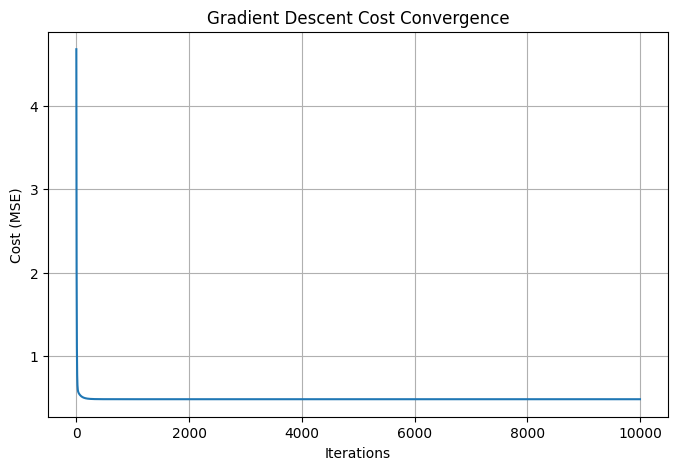

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iterations")

plt.ylabel("Cost (MSE)")

plt.title("Gradient Descent Cost Convergence")

plt.grid(True)

plt.show()

In [17]:
y_pred_scaled = hypothesis(X_test_bias, theta)

y_pred = y_pred_scaled * y_scale

print("Actual Prices:", y_test[:10])

print("\nPredicted Prices:", y_pred[:10])

Actual Prices: [ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

Predicted Prices: [ 63969.11055232 154577.11890465 253305.72773352 263740.26827229
 267115.8801221  155636.02474697 287291.17013655 223893.29838961
 257277.55111939 404505.88424937]


In [18]:
def calculate_mse(actual, predicted):

    mse = np.mean((actual - predicted) ** 2)

    return mse


mse = calculate_mse(y_test, y_pred)

print("Test MSE:", mse)

Test MSE: 5059655983.751342


In [19]:
def calculate_r2(actual, predicted):

    ss_res = np.sum((actual - predicted) ** 2)

    ss_total = np.sum((actual - np.mean(actual)) ** 2)

    r2 = 1 - (ss_res / ss_total)

    return r2


r2 = calculate_r2(y_test, y_pred)

print("Test R2 Score:", r2)

Test R2 Score: 0.6138872620864173


In [20]:
X_simple_train = X_train_scaled[:, [7]]

X_simple_test = X_test_scaled[:, [7]]

X_simple_train_bias = add_intercept(X_simple_train)

X_simple_test_bias = add_intercept(X_simple_test)

print("Simple training shape:", X_simple_train_bias.shape)

print("Simple testing shape:", X_simple_test_bias.shape)

Simple training shape: (16512, 2)
Simple testing shape: (4128, 2)


In [21]:
simple_theta, simple_cost_history = gradient_descent(
    X_simple_train_bias,
    y_train_scaled,
    learning_rate=0.05,
    iterations=10000
)

print("Simple Linear Regression Training Completed!")

print("Learned Parameters:", simple_theta)

Simple Linear Regression Training Completed!
Learned Parameters: [2.07194694 0.79851956]


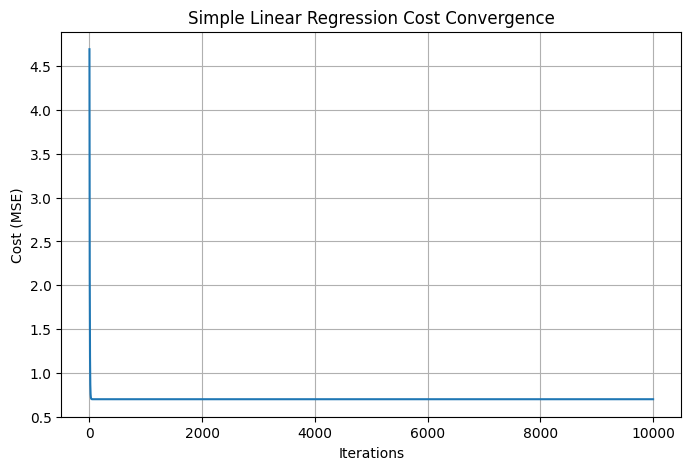

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(simple_cost_history)

plt.xlabel("Iterations")

plt.ylabel("Cost (MSE)")

plt.title("Simple Linear Regression Cost Convergence")

plt.grid(True)

plt.show()

In [23]:
simple_pred_scaled = hypothesis(
    X_simple_test_bias,
    simple_theta
)

simple_predictions = simple_pred_scaled * y_scale

print("Actual Values:", y_test[:10])

print("\nSimple Regression Predictions:")
print(simple_predictions[:10])

Actual Values: [ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

Simple Regression Predictions:
[114958.91676996 150606.88213964 190393.71844449 285059.38345102
 200663.31816103 242165.24890609 257647.22610228 199229.18051176
 245893.1681172  384677.43607096]


In [24]:
simple_mse = calculate_mse(y_test, simple_predictions)

simple_r2 = calculate_r2(y_test, simple_predictions)

print("Simple Linear Regression Results")

print("MSE:", simple_mse)

print("R2 Score:", simple_r2)

Simple Linear Regression Results
MSE: 7091157771.76555
R2 Score: 0.45885918903846656


In [25]:
sk_model = LinearRegression()

sk_model.fit(X_train_scaled, y_train)

sk_predictions = sk_model.predict(X_test_scaled)

print("Scikit-learn Model Trained Successfully!")

Scikit-learn Model Trained Successfully!


In [26]:
sk_mse = calculate_mse(y_test, sk_predictions)

sk_r2 = calculate_r2(y_test, sk_predictions)

print("Scikit-learn Results")

print("MSE:", sk_mse)

print("R2 Score:", sk_r2)

Scikit-learn Results
MSE: 5059656033.126063
R2 Score: 0.6138872583185309


In [27]:
comparison = pd.DataFrame({

    "Metric": ["MSE", "R2 Score"],

    "NumPy From Scratch": [mse, r2],

    "Scikit-learn": [sk_mse, sk_r2]

})

print(comparison)

     Metric  NumPy From Scratch  Scikit-learn
0       MSE        5.059656e+09  5.059656e+09
1  R2 Score        6.138873e-01  6.138873e-01


In [28]:
scratch_coefficients = theta[1:] * y_scale

coefficient_comparison = pd.DataFrame({

    "Feature": features,

    "NumPy Coefficients": scratch_coefficients,

    "Scikit-learn Coefficients": sk_model.coef_

})

print(coefficient_comparison)

print("\nIntercept Comparison:")

print("NumPy:", theta[0] * y_scale)

print("Scikit-learn:", sk_model.intercept_)

              Feature  NumPy Coefficients  Scikit-learn Coefficients
0           longitude       -85503.217489              -85503.218153
1            latitude       -90698.848314              -90698.848803
2  housing_median_age        14905.906396               14905.906448
3         total_rooms       -17805.416703              -17805.418501
4      total_bedrooms        48712.334578               48712.343341
5          population       -43766.492785              -43766.491159
6          households        17654.509185               17654.500659
7       median_income        77194.698962               77194.699466

Intercept Comparison:
NumPy: 207194.69373788786
Scikit-learn: 207194.69373788807


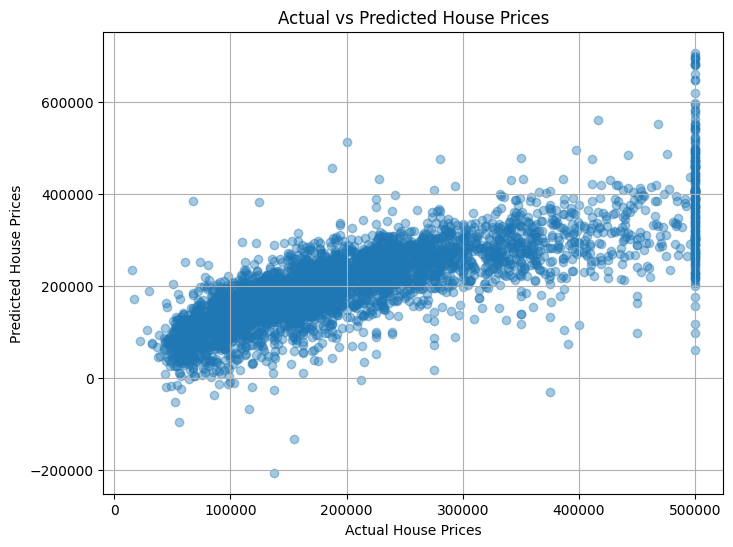

In [29]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual House Prices")

plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.grid(True)

plt.show()

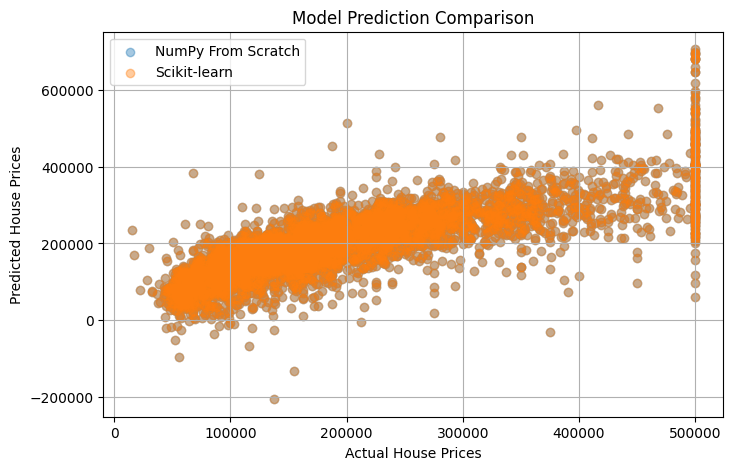

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4,
    label="NumPy From Scratch"
)

plt.scatter(
    y_test,
    sk_predictions,
    alpha=0.4,
    label="Scikit-learn"
)

plt.xlabel("Actual House Prices")

plt.ylabel("Predicted House Prices")

plt.title("Model Prediction Comparison")

plt.legend()

plt.grid(True)

plt.show()

In [31]:
final_results = pd.DataFrame({

    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression (NumPy)",
        "Multiple Linear Regression (Scikit-learn)"
    ],

    "MSE": [
        simple_mse,
        mse,
        sk_mse
    ],

    "R2 Score": [
        simple_r2,
        r2,
        sk_r2
    ]

})

print(final_results)

                                       Model           MSE  R2 Score
0                   Simple Linear Regression  7.091158e+09  0.458859
1         Multiple Linear Regression (NumPy)  5.059656e+09  0.613887
2  Multiple Linear Regression (Scikit-learn)  5.059656e+09  0.613887
